In [1]:
import rbfopt
import numpy as np
import warnings
warnings.filterwarnings("ignore", message="Signature .* for <class 'numpy.longdouble'> does not match any known type")
import csv

/home/albertlee/miniconda3/envs/rbfopt/lib/python3.13/site-packages/numpy/_core/getlimits.py:551: UserWarning: Signature b'\x00\xd0\xcc\xcc\xcc\xcc\xcc\xcc\xfb\xbf\x00\x00\x00\x00\x00\x00' for <class 'numpy.longdouble'> does not match any known type: falling back to type probe function.
This warnings indicates broken support for the dtype!
  machar = _get_machar(dtype)


In [2]:
def load_grid(filename="compl_enum_cstr_30_baron_hull.csv"):
    """
    Load grid data from CSV.
    Expected CSV columns: "x", "y", "Objective", among others.
    Returns a dictionary mapping (x, y) tuples to the objective value.
    """
    grid_data = {}
    with open(filename, "r") as f:
        reader = csv.DictReader(f)
        for row in reader:
            try:
                # Convert x and y values to integers
                x_val = int(row["x"])
                y_val = int(row["y"])
                # Skip rows where either x or y is greater than 7
                if x_val > 17 or y_val > 17:
                    continue
                # Convert objective value to float
                obj_val = float(row["Objective"])
                grid_data[(x_val, y_val)] = obj_val
            except Exception as e:
                # Skip rows with conversion issues
                continue
    return grid_data
# Load the data from grid.csv
grid_data = load_grid()

# Determine grid bounds from the keys of grid_data
xs = [pt[0] for pt in grid_data.keys()]
ys = [pt[1] for pt in grid_data.keys()]
min_x, max_x = min(xs), max(xs)
min_y, max_y = min(ys), max(ys)
print("Grid bounds:")
print("x in [{}, {}]".format(min_x, max_x))
print("y in [{}, {}]".format(min_y, max_y))

Grid bounds:
x in [1, 17]
y in [1, 17]


In [3]:
# Load the data from grid.csv
grid_data = load_grid()

# PENALTY = 1e5  # adjust this penalty as appropriate
PENALTY = np.inf # use infinity as penalty for infeasible points
# PENALTY = np.nan  # use NaN as penalty for infeasible points
# PENALTY = None  # use None as penalty for infeasible points

def obj_funct(x):
    """
    Given a candidate point x (a list or 1-D numpy array with 2 elements),
    this function rounds x to the nearest integers and returns the objective value
    if the point exists in grid_data and is feasible (i.e. y <= x).
    Otherwise, returns a penalty value.
    """
    # Round the candidate coordinates to nearest integers
    x_int = int(round(x[0]))
    y_int = int(round(x[1]))
    
    # Check the feasibility of the point: for our lattice we require y <= x.
    if y_int > x_int:
        return PENALTY
    
    # If the point exists in the grid, return its objective value.
    if (x_int, y_int) in grid_data:
        return grid_data[(x_int, y_int)]
    else:
        # If the point is not in the grid, return the penalty.
        return PENALTY

In [4]:
test_point = [17,17]
value = obj_funct(test_point)
print(f"For point {test_point} the objective value is {value}")

For point [17, 17] the objective value is 2.81525078099529


In [5]:
# Set up the black-box for a 2D problem with integer variables.
# We use the determined bounds and mark both variables as integer ("I").
black_box = rbfopt.RbfoptUserBlackBox(
    2,                   # number of variables
    np.array([1, 1]),    # lower bounds for x and y
    np.array([7, 7]),    # upper bounds for x and y
    np.array(["I", "I"]),# both variables are integers
    obj_funct
)

# Configure optimization settings.
settings = rbfopt.RbfoptSettings(
    max_evaluations=10,  # maximum number of evaluations
    minlp_solver_path='/home/albertlee/ampl.linux-intel64/bonmin',
    nlp_solver_path='/home/albertlee/ampl.linux-intel64/ipopt',
    algorithm='MSRSM',   # optimization algorithm variant
    rbf='auto',           # allow automatic RBF selection
    global_search_method = 'solver',  # options = ['sampling', 'genetic', 'solver']
)

# Create the optimization algorithm instance.
alg = rbfopt.RbfoptAlgorithm(settings, black_box)

# Run the optimization.
best_val, best_point, itercount, evalcount, fast_evalcount = alg.optimize()

print("Optimization completed.")
print("Best objective value found:", best_val)
print("At lattice point (rounded):", [int(round(v)) for v in best_point])
print("Iterations:", itercount, "Function evaluations:", evalcount)

  Iter  Cycle  Action             Objective value      Time      Gap
  ----  -----  ------             ---------------      ----      ---
     0      0  Initialization            2.965911      0.02   100.00 *
     0      0  Initialization            4.061882      0.02   100.00  
     0      0  Initialization            3.133784      0.03   100.00  
     0      0  GlobalStep                     inf      0.67   100.00  
     1      0  GlobalStep                3.287151      1.07   100.00  
     2      0  GlobalStep                     inf      1.56   100.00  
     3      0  GlobalStep                3.269434      1.81   100.00  
     4      0  GlobalStep                3.007278      2.19   100.00  
     5      1  Discarded                               2.91
     6      1  GlobalStep                3.062015      3.44   100.00  
     7      1  GlobalStep                     inf      4.31   100.00  
Summary: iters   8 evals  10 noisy_evals   0 cycles   1 opt_time    4.31 tot_time    4.31 ob

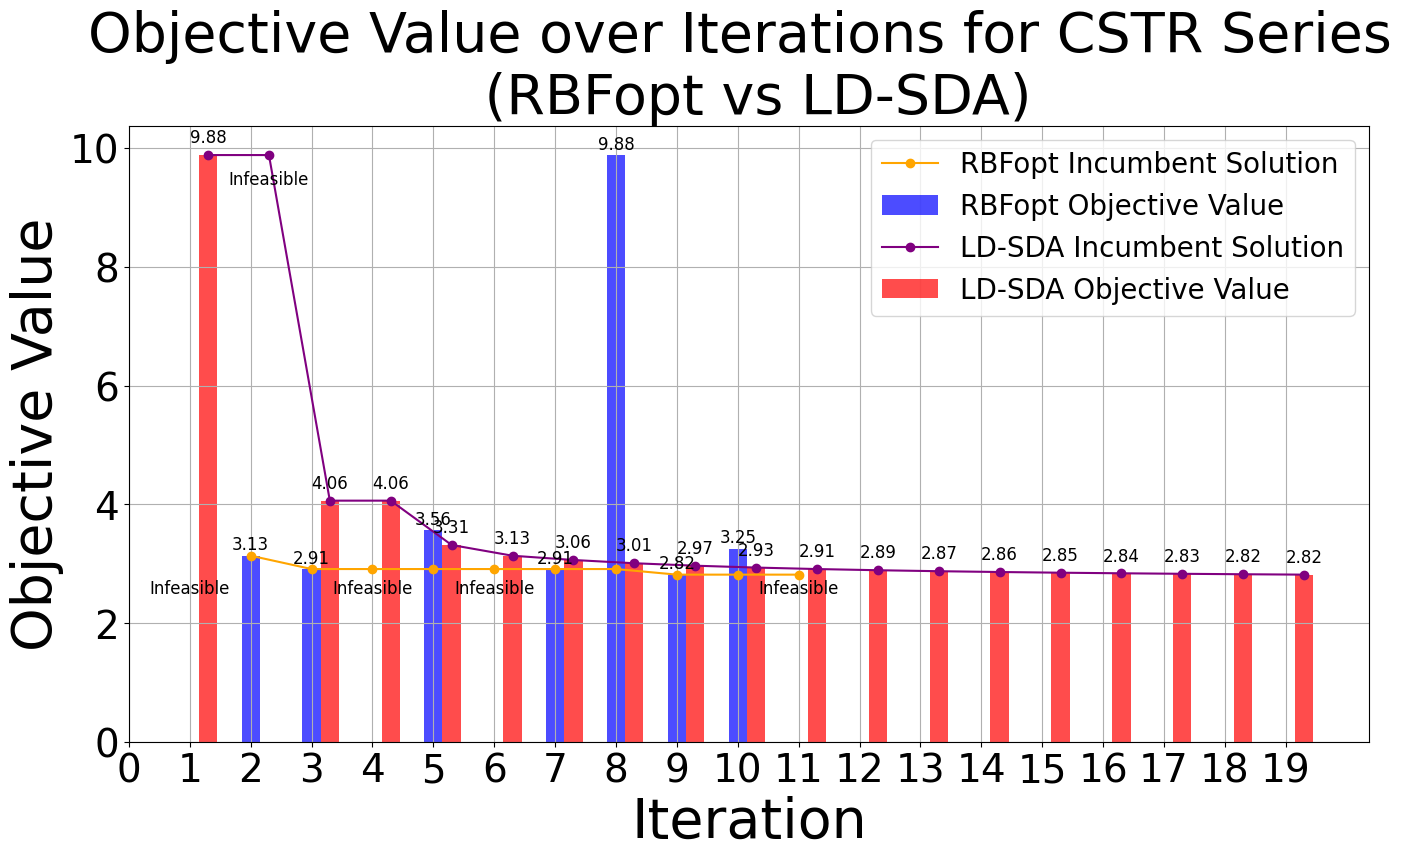

In [6]:
import matplotlib.pyplot as plt
import numpy as np
# Trajectory: 
# Iter   0 Obj             inf Point [16. 17.]
# Iter   1 Obj        3.134337 Point [4. 1.]
# Iter   2 Obj        2.909511 Point [9. 9.]
# Iter   3 Obj             inf Point [ 1. 17.]
# Iter   4 Obj        3.561959 Point [15.  1.]
# Iter   5 Obj             inf Point [ 4. 17.]
# Iter   6 Obj        2.909511 Point [9. 9.]
# Iter   7 Obj        9.884852 Point [1. 1.]
# Iter   8 Obj        2.815251 Point [17. 17.]
# Iter   9 Obj        3.252993 Point [14. 12.]
# Iter  10 Obj             inf Point [16. 17.]
# Iter  11 Obj        3.328494 Point [17. 14.]

# Optimization completed.
# Best objective value found: 2.81525078099529
# At lattice point (rounded): [17, 17]
# Iterations: 23 Function evaluations: 10

iterations = [
    (1, float("inf"), [16, 17]),
    (2, 3.134337, [4, 1]),
    (3, 2.909511, [9, 9]),
    (4, float("inf"), [1, 17]),
    (5, 3.561959, [15, 1]),
    (6, float("inf"), [4, 17]),
    (7, 2.909511, [9, 9]),
    (8, 9.884852, [1, 1]),
    (9, 2.815251, [17, 17]),
    (10, 3.252993, [14, 12]),
    (11, float("inf"), [16, 17]),
    # (12, 3.328494, [17, 14]),
    # (13, 2.981420, [17, 16]),
    # (14, float("inf"), [8, 9]),
    # (15, 3.176974, [10, 9]),
    # (16, 3.156468, [17, 15]),
    # (17, float("inf"), [14, 15]),
    # (18, 3.587653, [17, 1]),
    # (19, float("inf"), [9, 10])
]

neighborhood = [
    (9.884851863760804, 1.0, 1.0),
    (4.061881684250354, 2.0, 2.0),
]

line_search = [
    (1,1,9.884851863760804),
    (2,2,4.061881684250354),
    (3,3,3.3148454030723937),
    (4,4,3.1337838981128),
    (5,5,3.06201457641079),
    (6,6,3.0072779729074375),
    (7,7,2.965911187241821),
    (8,8,2.93438026379752,),
    (9,9,2.9095113779790474),
    (10,10,2.88953696810932),
    (11,11,2.873094081299025),
    (12,12,2.8594466153081886),
    (13,13,2.847885348284028),
    (14,14,2.837970119175829),
    (15,15,2.82939406018371),
    (16,16,2.82187639112928),
    (17,17,2.81525078099529)
]

LDSDA_iterations = [
    (1, 9.884851863760804, [1., 1.]),
    (2, float('inf'), [1., 2.]),
    (3, 4.061882, [2., 2.]),
    (4, 4.061882, [2., 1.]),
    (5, 3.3148454030723937, [3., 3.]),
    (6, 3.1337838981128, [4., 4.]),
    (7, 3.06201457641079, [5., 5.]),
    (8, 3.0072779729074375, [6., 6.]),
    (9, 2.965911187241821, [7., 7.]),
    (10, 2.93438026379752, [8., 8.]),
    (11, 2.9095113779790474, [9., 9.]),
    (12, 2.88953696810932, [10., 10.]),
    (13, 2.873094081299025, [11., 11.]),
    (14, 2.8594466153081886, [12., 12.]),
    (15, 2.847885348284028, [13., 13.]),
    (16, 2.837970119175829, [14., 14.]),
    (17, 2.82939406018371, [15., 15.]),
    (18, 2.82187639112928, [16., 16.]),
    (19, 2.81525078099529, [17., 17.])
]

FMQA_iterations = [
    (1, 3.546165612, [14, 8]),
    (2, 3.561946607, [15, 4]),
    (3, 3.399006302, [15, 12]),
    (4, 3.546159260, [14, 7]),
    (5, 2.859446615, [12, 12]),
    (6, 2.859446615, [12, 12]),
    (7, 2.859446615, [12, 12]),
    (8, 2.859446615, [12, 12]),
    (9, 2.859446615, [12, 12]),
    (10, 2.859446615, [12, 12])
]

# Extract iteration indices and objective values
RBFopt_indices = [pt[0] for pt in iterations]
RBFopt_obj = [pt[1] for pt in iterations]

LDSDA_indices = [pt[0] for pt in LDSDA_iterations]
LDSDA_obj = [pt[1] for pt in LDSDA_iterations]

# FMQA_indices = np.array([t[0] for t in FMQA_iterations], dtype=float)
# FMQA_obj     = np.array([t[1] for t in FMQA_iterations], dtype=float)

# Calculate best-so-far (ladder plot) for each method
RBFopt_best = [min(RBFopt_obj[:i+1]) for i in range(len(RBFopt_obj))]
LDSDA_best = [min(LDSDA_obj[:i+1]) for i in range(len(LDSDA_obj))]
# FMQA_best = np.minimum.accumulate(FMQA_obj)

# For annotations of infeasible bars, determine a fixed y-position
ldsda_feasible = [obj for obj in LDSDA_obj if not np.isinf(obj)]
ldsda_feasible_max = max(ldsda_feasible) if ldsda_feasible else 1

fig, ax = plt.subplots(figsize=(16, 8))
bar_width = 0.3

# Convert indices to numpy arrays for arithmetic
RBFopt_x = np.array(RBFopt_indices, dtype=float)
LDSDA_x = np.array(LDSDA_indices, dtype=float)

# bars_fmqa = ax.bar(FMQA_indices - bar_width, FMQA_obj, width=bar_width,
#                    label="FMQA Objective Value", color="green")
# line_fmqa, = ax.plot(FMQA_indices - bar_width, FMQA_best, marker="o", linestyle="-",
#                      color="#90ee90", label="FMQA Incumbent Solution")

# # Annotate FMQA bars 
# for x, y in zip(FMQA_indices, FMQA_obj):
#     ax.text(x - bar_width, y - 2.3, f"{y:.2f}", fontsize=12, ha="center")

# Plot RBFopt bars (shift left)
bars_rbf = ax.bar(RBFopt_x, RBFopt_obj, width=bar_width,
                  color='blue', alpha=0.7, label='RBFopt Objective Value')
# Annotate RBFopt bars
for x, obj in zip(RBFopt_x, RBFopt_obj):
    if np.isinf(obj):
        ax.text(x, 2.5, 'Infeasible', fontsize=12, color='black', ha='center')
    else:
        ax.text(x, obj + 0.1, f'{obj:.2f}', fontsize=12, color='black', ha='center')

# Plot RBFopt best-so-far (ladder) and store its handle
line_rbf, = ax.plot(
    RBFopt_x, RBFopt_best, marker='o', linestyle='-', color='orange',
    label='RBFopt Incumbent Solution', zorder=5
)


# Plot LD-SDA bars (shift right)
bars_ldsda = ax.bar(LDSDA_x + bar_width, LDSDA_obj, width=bar_width,
                    color='red', alpha=0.7, label='LD-SDA Objective Value')
# Annotate LD-SDA bars
for x, obj in zip(LDSDA_x, LDSDA_obj):
    if np.isinf(obj):
        ax.text(x + bar_width, ldsda_feasible_max * 0.95, 'Infeasible',
                fontsize=12, color='black', ha='center')
    else:
        ax.text(x + bar_width, obj + 0.21, f'{obj:.2f}',
                fontsize=12, color='black', ha='center')


# Plot LD-SDA best-so-far (ladder) and store its handle
line_ldsda, = ax.plot(LDSDA_x + bar_width, LDSDA_best, marker='o', linestyle='-', color='purple',
                      label='LD-SDA Incumbent Solution')

# Now manually set the legend order by specifying handles in the desired sequence
ax.legend(
    [ # line_fmqa, 
    # bars_fmqa, 
    line_rbf, bars_rbf, line_ldsda, bars_ldsda], 
    [
        # 'FMQA Incumbent Solution', 'FMQA Objective Value',
        'RBFopt Incumbent Solution', 'RBFopt Objective Value',
        'LD-SDA Incumbent Solution', 'LD-SDA Objective Value'
    ],
    fontsize=20, ncol=1
)

# Labeling and styling
ax.set_xlabel('Iteration', fontsize=40)
ax.set_ylabel('Objective Value', fontsize=40)
ax.set_title('Objective Value over Iterations for CSTR Series \n (RBFopt vs LD-SDA)', fontsize=40)
ax.grid(True)

# Set x-axis ticks
max_iter = max(max(RBFopt_indices), 
max(LDSDA_indices), 
# max(FMQA_indices)
)
ax.set_xticks(np.arange(0, max_iter + 1, 1))
ax.tick_params(axis='y', labelsize=28)
ax.tick_params(axis='x', labelsize=28)

plt.show()



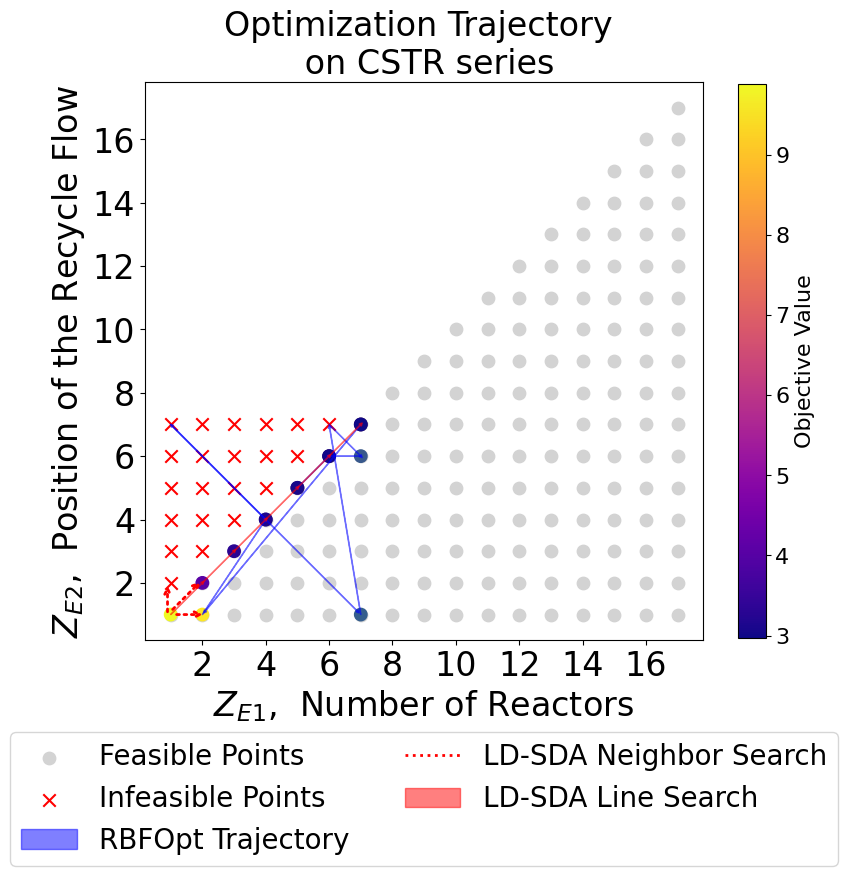

In [7]:
import matplotlib.pyplot as plt
import numpy as np
# Data from the iterations
# iterations = [
#     (0, float('inf'), [27., 30.]),
#     (1, 3.287151, [7., 1.]),
#     (2, 2.821876, [16., 16.]),
#     (3, float('inf'), [1., 30.]),
#     (4, 3.652690, [26., 1.]),
#     (5, float('inf'), [7., 30.]),
#     (6, 2.821876, [16., 16.]),
#     (7, 9.884852, [1., 1.]),
#     (8, 2.769570, [30., 30.]),
#     (9, 3.248530, [25., 21.]),
#     (10, float('inf'), [29., 30.]),
#     (11, 3.256144, [30., 25.]),
#     (12, 2.860112, [30., 29.]),
#     (13, float('inf'), [15., 16.]),
#     (14, 2.981420, [17., 16.]),
#     (15, 3.156468, [17., 15.]),
#     (16, 2.954869, [30., 28.]),
#     (17, 2.781482, [25., 25.]),
#     (18, 3.561959, [15., 3.]),
#     (19, float('inf'), [1., 30.]),
#     (20, float('inf'), [18., 22.]),
#     (21, float('inf'), [17., 18.]),
#     (22, 2.884106, [26., 25.]),
#     (23, float('inf'), [25., 26.]),
#     (24, 3.200915, [6., 4.]),
#     (25, 3.668707, [30., 11.]),
#     (26, 2.891356, [25., 24.]),
# ]


# new iterations data
iterations = [
    (0, 2.965911, [7., 7.]),
    (1, 4.061882, [2., 1.]),
    (2, 3.133784, [4., 4.]),
    (3, float('inf'), [1., 7.]),
    (4, 3.287151, [7., 1.]),
]

# 9 iterations data
iterations = [
    (0, 2.965911, [7., 7.]),
    (1, 4.061882, [2., 1.]),
    (2, 3.133784, [4., 4.]),
    (3, float('inf'), [1., 7.]),
    (4, 3.287151, [7., 1.]),
    (5, float('inf'), [6., 7.]),
    (6, 3.269434, [7., 6.]),
    (7, 3.007278, [6., 6.]),
    (8, 3.062015, [5., 5.]),
]


# Trajectory: 
# Iter   0 Obj        2.965911 Point [7. 7.]
# Iter   1 Obj        4.061882 Point [2. 1.]
# Iter   2 Obj        3.133784 Point [4. 4.]
# Iter   3 Obj             inf Point [1. 7.]
# Iter   4 Obj        3.287151 Point [7. 1.]
# Iter   5 Obj             inf Point [6. 7.]
# Iter   6 Obj        3.269434 Point [7. 6.]
# Iter   7 Obj        3.007278 Point [6. 6.]
# Iter   8 Obj        3.062015 Point [5. 5.]


neighborhood = [
    (9.884851863760804, 1.0, 1.0),
    (4.061881684250354, 2.0, 2.0),
]

line_search = [
    (1,1,9.884851863760804),
    (2,2,4.061881684250354),
    (3,3,3.3148454030723937),
    (4,4,3.1337838981128),
    (5,5,3.06201457641079),
    (6,6,3.0072779729074375),
    (7,7,2.965911187241821)
]


# Extract x, y, and objective values
trajectory_x = [point[2][0] for point in iterations]
trajectory_y = [point[2][1] for point in iterations]
trajectory_obj = [point[1] for point in iterations]

# Extract the line search points
line_search_x = [point[0] for point in line_search]
line_search_y = [point[1] for point in line_search]
line_search_obj = [point[2] for point in line_search]

# Plot the trajectory
plt.figure(figsize=(9, 9))                 # Square figure size
plt.gca().set_aspect('equal', 'box')       # Equal aspect ratio on x and y

plt.scatter(xs, ys, c='lightgray', label= 'Feasible Points', s=80)  # Plot the grid points


# 2) Mark all infeasible points where y > x
infeasible_mask = [(1,2), (1,3), (1,4), (1,5), (1,6), (1,7),
                   (2,3), (2,4), (2,5), (2,6), (2,7),
                   (3,4), (3,5), (3,6), (3,7),
                   (4,5), (4,6), (4,7),
                   (5,6), (5,7),
                   (6,7)]
plt.scatter(*zip(*infeasible_mask), c='red', label='Infeasible Points', s=80, marker='x')  # Plot infeasible points

plt.scatter(trajectory_x, trajectory_y, c=trajectory_obj, cmap='viridis', s=80)#, label='Trajectory')  # Plot the trajectory
plt.scatter(line_search_x, line_search_y, c=line_search_obj, cmap='plasma', marker='o', s=80)#, label='Line Search Points')  # Plot line search points
# plt.colorbar(label='Objective Value', shrink=0.8)  # Add color bar for trajectory points
cbar = plt.colorbar(label='Objective Value', shrink=0.8)
cbar.set_label('Objective Value', fontsize=16)
cbar.ax.tick_params(labelsize=16)

# plt.scatter(best_point[0], best_point[1], c='red', label='Best Point', edgecolors='black')  # Highlight the best point
# Add arrow following evaluation sequence
for i in range(len(trajectory_x) - 1):
    plt.arrow(
        trajectory_x[i], 
        trajectory_y[i],
        0.98*(trajectory_x[i+1] - trajectory_x[i]), 
        0.98*(trajectory_y[i+1] - trajectory_y[i]),
        head_width=0.1,   # smaller head width
        head_length=0.1,  # smaller head length
        width=0.01,       # optional: reduces the thickness of the arrow shaft
        fc='blue', 
        ec='blue', 
        alpha=0.5,
        label='RBFOpt Trajectory' if i == 0 else ""  # Only label the first arrow
    )

# Base point for neighbor search arrows
base = np.array([1, 1])

# Define the neighbor search endpoints
neighbors = np.array([
    [1, 2],
    [2, 2],
    [2, 1]
])

# Define small offsets for each arrow to avoid overlapping with the line search arrow at (1,1)
offsets = [
    np.array([-0.1, 0]),   # for arrow to (1,2): shift left
    np.array([0, 0.1]),    # for arrow to (2,2): shift up
    np.array([0.1, 0])     # for arrow to (2,1): shift right
]


# Create a dummy plot for legend entry (if needed)
plt.plot([], [], linestyle='dotted', color='red', lw=2, label='LD-SDA Neighbor Search')

# Draw the red dotted neighbor search arrows with offsets
for neighbor, offset in zip(neighbors, offsets):
    start = base + offset
    end = neighbor + offset
    plt.annotate("",
                 xy=end, xycoords='data',
                 xytext=start, textcoords='data',
                 arrowprops=dict(arrowstyle="->",
                                 linestyle="dotted",
                                 color="red",
                                 lw=2)
                )

for i in range(len(line_search_x) - 1):
    plt.arrow(
        line_search_x[i], 
        line_search_y[i],
        0.98*(line_search_x[i+1] - line_search_x[i]), 
        0.98*(line_search_y[i+1] - line_search_y[i]),
        head_width=0.1,   # smaller head width
        head_length=0.1,  # smaller head length
        width=0.01,       # optional: reduces the thickness of the arrow shaft
        fc='red', 
        ec='red', 
        alpha=0.5,
        label='LD-SDA Line Search' if i == 0 else ""  # Only label the first arrow
    )

# # Add iteration number next to each point
# for i, (x, y) in enumerate(zip(trajectory_x, trajectory_y)):
#     plt.text(x + 0.1, y + 0.05, str(i), fontsize=12, color='black')
ext1_name='Z_E, Number of Reactors'
ext2_name='Z_E, Position of the Recycle Flow'
plt.xlabel('$Z_{E1}$, ' + ext1_name.split('Z_E,')[1] if 'Z_E,' in ext1_name else ext1_name, fontsize=24)
plt.ylabel('$Z_{E2}$, ' + ext2_name.split('Z_E,')[1] if 'Z_E,' in ext2_name else ext2_name, fontsize=24)
plt.xticks(fontsize=24)
plt.yticks(fontsize=24)
plt.title('Optimization Trajectory \n on CSTR series', fontsize=24)
plt.legend(
    loc='upper center',        # anchor in the middle (horizontally)
    bbox_to_anchor=(0.5, -0.14),  # shift legend below the plot
    fancybox=True,
    shadow=False,
    ncol=2,                   # number of columns in the legend
    fontsize=20
)
plt.show()

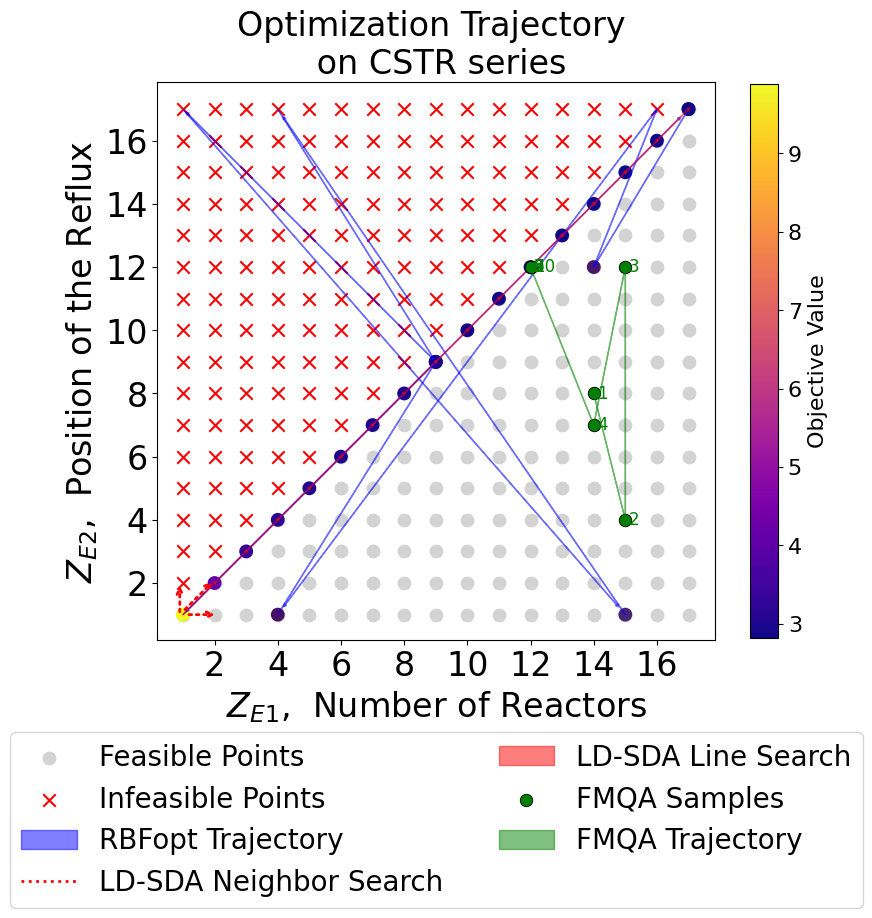

In [8]:
import matplotlib.pyplot as plt
import numpy as np
# Trajectory: 
# Iter   0 Obj             inf Point [16. 17.]
# Iter   1 Obj        3.134337 Point [4. 1.]
# Iter   2 Obj        2.909511 Point [9. 9.]
# Iter   3 Obj             inf Point [ 1. 17.]
# Iter   4 Obj        3.561959 Point [15.  1.]
# Iter   5 Obj             inf Point [ 4. 17.]
# Iter   6 Obj        2.909511 Point [9. 9.]
# Iter   7 Obj        9.884852 Point [1. 1.]
# Iter   8 Obj        2.815251 Point [17. 17.]
# Iter   9 Obj        3.252993 Point [14. 12.]
# Iter  10 Obj             inf Point [16. 17.]
# Iter  11 Obj        3.328494 Point [17. 14.]

# Optimization completed.
# Best objective value found: 2.81525078099529
# At lattice point (rounded): [17, 17]
# Iterations: 23 Function evaluations: 10

iterations = [
    (1, float("inf"), [16, 17]),
    (2, 3.134337, [4, 1]),
    (3, 2.909511, [9, 9]),
    (4, float("inf"), [1, 17]),
    (5, 3.561959, [15, 1]),
    (6, float("inf"), [4, 17]),
    (7, 2.909511, [9, 9]),
    (8, 9.884852, [1, 1]),
    (9, 2.815251, [17, 17]),
    (10, 3.252993, [14, 12]),
    (11, float("inf"), [16, 17]),
    # (12, 3.328494, [17, 14]),
    # (13, 2.981420, [17, 16]),
    # (14, float("inf"), [8, 9]),
    # (15, 3.176974, [10, 9]),
    # (16, 3.156468, [17, 15]),
    # (17, float("inf"), [14, 15]),
    # (18, 3.587653, [17, 1]),
    # (19, float("inf"), [9, 10])
]

neighborhood = [
    (9.884851863760804, 1.0, 1.0),
    (4.061881684250354, 2.0, 2.0),
]

line_search = [
    (1,1,9.884851863760804),
    (2,2,4.061881684250354),
    (3,3,3.3148454030723937),
    (4,4,3.1337838981128),
    (5,5,3.06201457641079),
    (6,6,3.0072779729074375),
    (7,7,2.965911187241821),
    (8,8,2.93438026379752,),
    (9,9,2.9095113779790474),
    (10,10,2.88953696810932),
    (11,11,2.873094081299025),
    (12,12,2.8594466153081886),
    (13,13,2.847885348284028),
    (14,14,2.837970119175829),
    (15,15,2.82939406018371),
    (16,16,2.82187639112928),
    (17,17,2.81525078099529)
]

LDSDA_iterations = [
    (1, 9.884851863760804, [1., 1.]),
    (2, float('inf'), [1., 2.]),
    (3, 4.061882, [2., 2.]),
    (4, 4.061882, [2., 1.]),
    (5, 3.3148454030723937, [3., 3.]),
    (6, 3.1337838981128, [4., 4.]),
    (7, 3.06201457641079, [5., 5.]),
    (8, 3.0072779729074375, [6., 6.]),
    (9, 2.965911187241821, [7., 7.]),
    (10, 2.93438026379752, [8., 8.]),
    (11, 2.9095113779790474, [9., 9.]),
    (12, 2.88953696810932, [10., 10.]),
    (13, 2.873094081299025, [11., 11.]),
    (14, 2.8594466153081886, [12., 12.]),
    (15, 2.847885348284028, [13., 13.]),
    (16, 2.837970119175829, [14., 14.]),
    (17, 2.82939406018371, [15., 15.]),
    (18, 2.82187639112928, [16., 16.]),
    (19, 2.81525078099529, [17., 17.])
]

FMQA_iterations = [
    (1, 3.546165612, [14, 8]),
    (2, 3.561946607, [15, 4]),
    (3, 3.399006302, [15, 12]),
    (4, 3.546159260, [14, 7]),
    (5, 2.859446615, [12, 12]),
    (6, 2.859446615, [12, 12]),
    (7, 2.859446615, [12, 12]),
    (8, 2.859446615, [12, 12]),
    (9, 2.859446615, [12, 12]),
    (10, 2.859446615, [12, 12])
]


# Extract x, y, and objective values
trajectory_x = [point[2][0] for point in iterations]
trajectory_y = [point[2][1] for point in iterations]
trajectory_obj = [point[1] for point in iterations]

# Extract the line search points
line_search_x = [point[0] for point in line_search]
line_search_y = [point[1] for point in line_search]
line_search_obj = [point[2] for point in line_search]

# Plot the trajectory
plt.figure(figsize=(9, 9))                 # Square figure size
plt.gca().set_aspect('equal', 'box')       # Equal aspect ratio on x and y

plt.scatter(xs, ys, c='lightgray', label= 'Feasible Points', s=80)  # Plot the grid points


# 2) Mark all infeasible points where y > x
infeasible_mask = [(1,2), (1,3), (1,4), (1,5), (1,6), (1,7), (1,8), (1,9), (1,10), (1,11), (1,12),  (1,13), (1,14), (1,15), (1,16), (1,17),
                   (2,3), (2,4), (2,5), (2,6), (2,7), (2,8), (2,9), (2,10), (2,11), (2,12), (2,13), (2,14), (2,15), (2,16), (2,17),
                   (3,4), (3,5), (3,6), (3,7), (3,8), (3,9), (3,10), (3,11), (3,12), (3,13), (3,14), (3,15), (3,16), (3,17),
                   (4,5), (4,6), (4,7), (4,8), (4,9), (4,10), (4,11), (4,12), (4,13), (4,14), (4,15), (4,16), (4,17),
                   (5,6), (5,7), (5,8), (5,9), (5,10), (5,11), (5,12), (5,13), (5,14), (5,15), (5,16), (5,17),
                   (6,7), (6,8), (6,9), (6,10), (6,11), (6,12), (6,13), (6,14), (6,15), (6,16), (6,17),
                   (7,8), (7,9), (7,10), (7,11), (7,12), (7,13), (7,14), (7,15), (7,16), (7,17),
                   (8,9), (8,10), (8,11), (8,12), (8,13), (8,14), (8,15), (8,16), (8,17),
                   (9,10), (9,11), (9,12), (9,13), (9,14), (9,15), (9,16), (9,17),
                   (10,11), (10,12), (10,13), (10,14), (10,15), (10,16), (10,17),
                   (11,12), (11,13), (11,14), (11,15), (11,16), (11,17),
                   (12,13), (12,14), (12,15), (12,16), (12,17),
                   (13,14), (13,15), (13,16), (13,17),
                   (14,15), (14,16), (14,17),
                   (15,16), (15,17),
                   (16,17)]
plt.scatter(*zip(*infeasible_mask), c='red', label='Infeasible Points', s=80, marker='x')  # Plot infeasible points

plt.scatter(trajectory_x, trajectory_y, c=trajectory_obj, cmap='viridis', s=80)#, label='Trajectory')  # Plot the trajectory
plt.scatter(line_search_x, line_search_y, c=line_search_obj, cmap='plasma', marker='o', s=80)#, label='Line Search Points')  # Plot line search points
# plt.colorbar(label='Objective Value', shrink=0.8)  # Add color bar for trajectory points
cbar = plt.colorbar(label='Objective Value', shrink=0.8)
cbar.set_label('Objective Value', fontsize=16)
cbar.ax.tick_params(labelsize=16)

# plt.scatter(best_point[0], best_point[1], c='red', label='Best Point', edgecolors='black')  # Highlight the best point
# Add arrow following evaluation sequence
for i in range(len(trajectory_x) - 1):
    plt.arrow(
        trajectory_x[i], 
        trajectory_y[i],
        0.98*(trajectory_x[i+1] - trajectory_x[i]), 
        0.98*(trajectory_y[i+1] - trajectory_y[i]),
        head_width=0.1,   # smaller head width
        head_length=0.1,  # smaller head length
        width=0.01,       # optional: reduces the thickness of the arrow shaft
        fc='blue', 
        ec='blue', 
        alpha=0.5,
        label='RBFopt Trajectory' if i == 0 else ""  # Only label the first arrow
    )

# Base point for neighbor search arrows
base = np.array([1, 1])

# Define the neighbor search endpoints
neighbors = np.array([
    [1, 2],
    [2, 2],
    [2, 1]
])

# Define small offsets for each arrow to avoid overlapping with the line search arrow at (1,1)
offsets = [
    np.array([-0.1, 0]),   # for arrow to (1,2): shift left
    np.array([0, 0.1]),    # for arrow to (2,2): shift up
    np.array([0.1, 0])     # for arrow to (2,1): shift right
]


# Create a dummy plot for legend entry (if needed)
plt.plot([], [], linestyle='dotted', color='red', lw=2, label='LD-SDA Neighbor Search')

# Draw the red dotted neighbor search arrows with offsets
for neighbor, offset in zip(neighbors, offsets):
    start = base + offset
    end = neighbor + offset
    plt.annotate("",
                 xy=end, xycoords='data',
                 xytext=start, textcoords='data',
                 arrowprops=dict(arrowstyle="->",
                                 linestyle="dotted",
                                 color="red",
                                 lw=2)
                )

for i in range(len(line_search_x) - 1):
    plt.arrow(
        line_search_x[i], 
        line_search_y[i],
        0.98*(line_search_x[i+1] - line_search_x[i]), 
        0.98*(line_search_y[i+1] - line_search_y[i]),
        head_width=0.1,   # smaller head width
        head_length=0.1,  # smaller head length
        width=0.01,       # optional: reduces the thickness of the arrow shaft
        fc='red', 
        ec='red', 
        alpha=0.5,
        label='LD-SDA Line Search' if i == 0 else ""  # Only label the first arrow
    )

# Extract FMQA lattice coords and objectives
fmqa_x = [t[2][0] for t in FMQA_iterations]
fmqa_y = [t[2][1] for t in FMQA_iterations]
fmqa_obj = [t[1]     for t in FMQA_iterations]

# Points (solid green; not tied to the plasma/viridis colorbar)
plt.scatter(fmqa_x, fmqa_y, c='green', s=80, marker='o',
            edgecolors='black', linewidths=0.6, label='FMQA Samples')

# Arrows following FMQA evaluation sequence (green)
for i in range(len(fmqa_x) - 1):
    plt.arrow(
        fmqa_x[i], fmqa_y[i],
        0.98*(fmqa_x[i+1] - fmqa_x[i]),
        0.98*(fmqa_y[i+1] - fmqa_y[i]),
        head_width=0.1,
        head_length=0.1,
        width=0.01,
        fc='green', ec='green', alpha=0.5,
        label='FMQA Trajectory' if i == 0 else ""   # only label first arrow
    )

# Iteration numbers for FMQA (green text)
for k, (x, y) in enumerate(zip(fmqa_x, fmqa_y), start=1):
    plt.text(x + 0.1, y - 0.15, str(k), fontsize=12, color='green')


# # Add iteration number next to each point
# for i, (x, y) in enumerate(zip(trajectory_x, trajectory_y)):
#     plt.text(x + 0.1, y + 0.05, str(i), fontsize=12, color='black')
ext1_name='Z_E, Number of Reactors'
ext2_name='Z_E, Position of the Reflux'
plt.xlabel('$Z_{E1}$, ' + ext1_name.split('Z_E,')[1] if 'Z_E,' in ext1_name else ext1_name, fontsize=24)
plt.ylabel('$Z_{E2}$, ' + ext2_name.split('Z_E,')[1] if 'Z_E,' in ext2_name else ext2_name, fontsize=24)
plt.xticks(fontsize=24)
plt.yticks(fontsize=24)
plt.title('Optimization Trajectory \n on CSTR series', fontsize=24)
plt.legend(
    loc='upper center',        # anchor in the middle (horizontally)
    bbox_to_anchor=(0.5, -0.14),  # shift legend below the plot
    fancybox=True,
    shadow=False,
    ncol=2,                   # number of columns in the legend
    fontsize=20
)
plt.show()

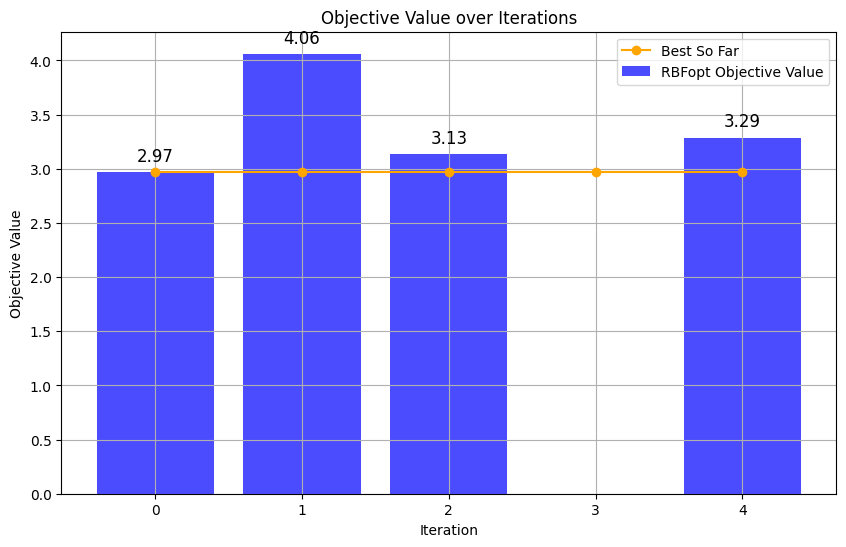

In [9]:
# new iterations data
iterations = [
    (0, 2.965911, [7., 7.]),
    (1, 4.061882, [2., 1.]),
    (2, 3.133784, [4., 4.]),
    (3, float('inf'), [1., 7.]),
    (4, 3.287151, [7., 1.]),
]

# Extract x, y, and objective values
trajectory_x = [point[2][0] for point in iterations]
trajectory_y = [point[2][1] for point in iterations]
trajectory_obj = [point[1] for point in iterations]


LDSDA_iterations = [
    (0, 9.884851863760804, [1., 1.]),
    (1, float('inf'), [1., 2.]),
    (2, 4.061882, [2., 2.]),
    (3, 4.061882, [2., 1.]),
    (4, 3.3148454030723937, [3., 3.]),
    (5, 3.1337838981128, [4., 4.]),
    (6, 3.06201457641079, [5., 5.]),
    (7, 3.0072779729074375, [6., 6.]),
    (8, 2.965911187241821, [7., 7.]),
]

# Plot objective against iteration
plt.figure(figsize=(10, 6))
# Bar plot with objectives for iteration and add a * for inf
plt.bar(range(len(trajectory_obj)), trajectory_obj, color='blue', alpha=0.7, label='RBFopt Objective Value')
# plt.bar(range(len(LDSDA_iterations)), [obj[1] for obj in LDSDA_iterations], color='red', alpha=0.7, label='LD-SDA Objective Value')
for i, obj in enumerate(trajectory_obj):
    if obj == np.inf:
        plt.text(i, obj + 0.1, '*', fontsize=12, color='red', ha='center')
    else:
        plt.text(i, obj + 0.1, f'{obj:.2f}', fontsize=12, color='black', ha='center')

# Ladder plot with the best found solution up until that iterations (minimum value)
best_so_far = [min(trajectory_obj[:i+1]) for i in range(len(trajectory_obj))]
plt.plot(range(len(trajectory_obj)), best_so_far, marker='o', linestyle='-', color='orange', label='Best So Far')

# plt.xticks(range(len(trajectory_obj)), [str(i) for i in range(len(trajectory_obj))])
plt.xlabel('Iteration')
plt.ylabel('Objective Value')

plt.title('Objective Value over Iterations')
plt.legend()
plt.grid()
plt.show()

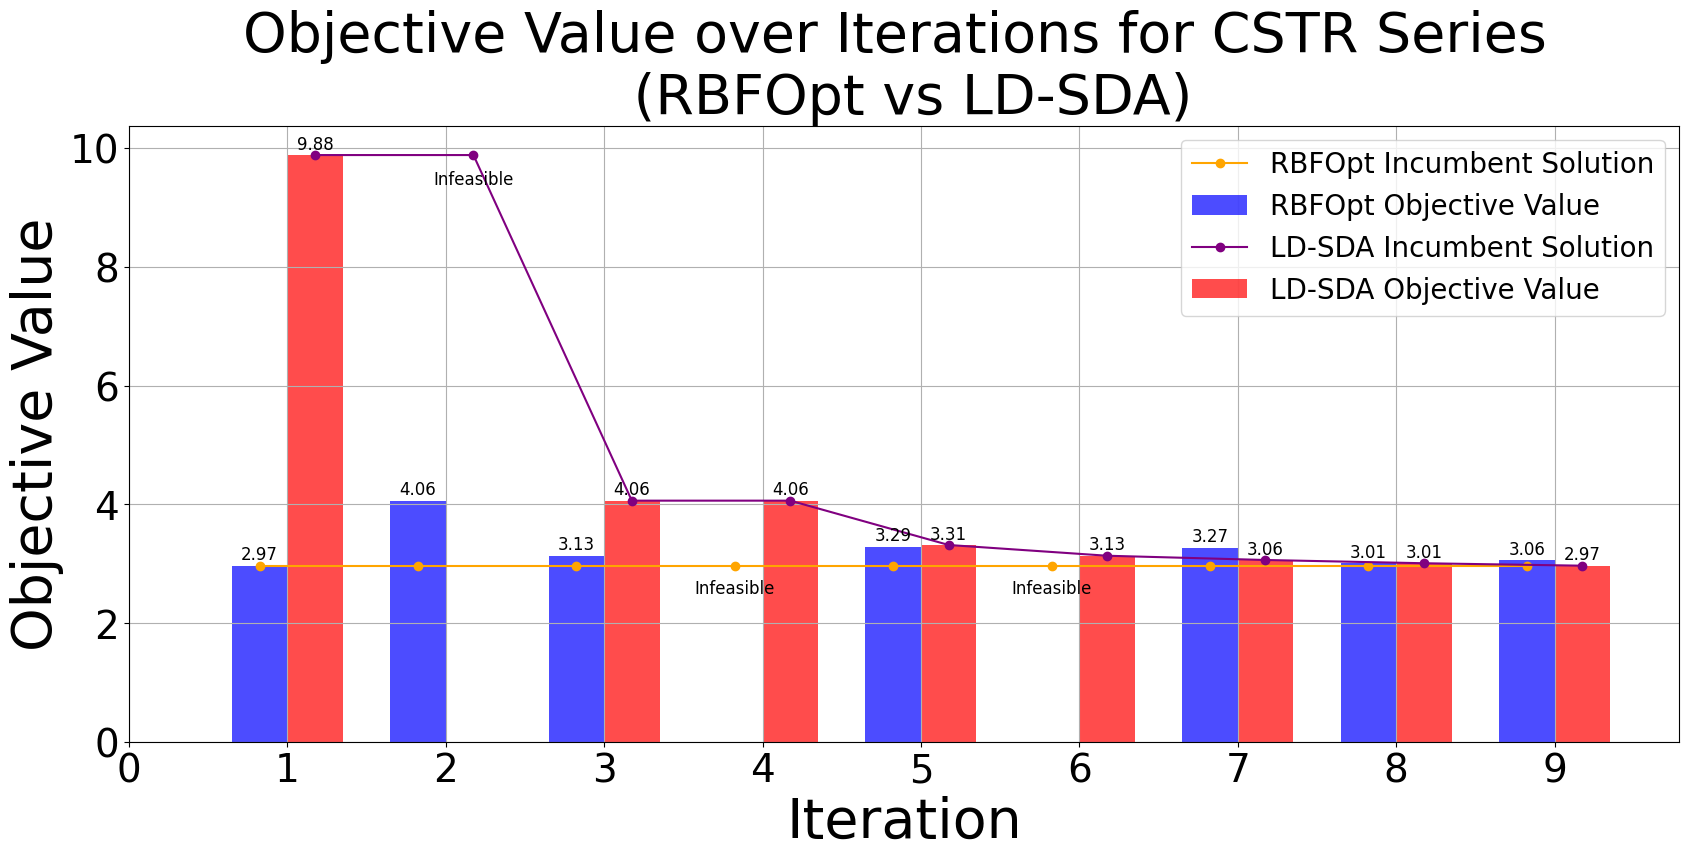

In [10]:
import matplotlib.pyplot as plt
import numpy as np

# # RBFopt iterations data
# iterations = [
#     (1, 2.965911, [7., 7.]),
#     (2, 4.061882, [2., 1.]),
#     (3, 3.133784, [4., 4.]),
#     (4, float('inf'), [1., 7.]),
#     (5, 3.287151, [7., 1.]),
# ]

# 9 iterations data
iterations = [
    (1, 2.965911, [7., 7.]),
    (2, 4.061882, [2., 1.]),
    (3, 3.133784, [4., 4.]),
    (4, float('inf'), [1., 7.]),
    (5, 3.287151, [7., 1.]),
    (6, float('inf'), [6., 7.]),
    (7, 3.269434, [7., 6.]),
    (8, 3.007278, [6., 6.]),
    (9, 3.062015, [5., 5.]),
]

# LD-SDA iterations data
LDSDA_iterations = [
    (1, 9.884851863760804, [1., 1.]),
    (2, float('inf'), [1., 2.]),
    (3, 4.061882, [2., 2.]),
    (4, 4.061882, [2., 1.]),
    (5, 3.3148454030723937, [3., 3.]),
    (6, 3.1337838981128, [4., 4.]),
    (7, 3.06201457641079, [5., 5.]),
    (8, 3.0072779729074375, [6., 6.]),
    (9, 2.965911187241821, [7., 7.]),
]

# Extract iteration indices and objective values
RBFopt_indices = [pt[0] for pt in iterations]
RBFopt_obj = [pt[1] for pt in iterations]

LDSDA_indices = [pt[0] for pt in LDSDA_iterations]
LDSDA_obj = [pt[1] for pt in LDSDA_iterations]

# Calculate best-so-far (ladder plot) for each method
RBFopt_best = [min(RBFopt_obj[:i+1]) for i in range(len(RBFopt_obj))]
LDSDA_best = [min(LDSDA_obj[:i+1]) for i in range(len(LDSDA_obj))]

# For annotations of infeasible bars, determine a fixed y-position
ldsda_feasible = [obj for obj in LDSDA_obj if not np.isinf(obj)]
ldsda_feasible_max = max(ldsda_feasible) if ldsda_feasible else 1

fig, ax = plt.subplots(figsize=(20, 8))
bar_width = 0.35

# Convert indices to numpy arrays for arithmetic
RBFopt_x = np.array(RBFopt_indices, dtype=float)
LDSDA_x = np.array(LDSDA_indices, dtype=float)

# Plot RBOpt bars (shift left)
bars_rbf = ax.bar(RBFopt_x - bar_width/2, RBFopt_obj, width=bar_width,
                  color='blue', alpha=0.7, label='RBFOpt Objective Value')
# Annotate RBFOpt bars
for x, obj in zip(RBFopt_x, RBFopt_obj):
    if np.isinf(obj):
        ax.text(x - bar_width/2, 2.5, 'Infeasible', fontsize=12, color='black', ha='center')
    else:
        ax.text(x - bar_width/2, obj + 0.1, f'{obj:.2f}', fontsize=12, color='black', ha='center')

# Plot RBOpt best-so-far (ladder) and store its handle
line_rbf, = ax.plot(RBFopt_x - bar_width/2, RBFopt_best, marker='o', linestyle='-', color='orange',
                    label='RBFOpt Incumbent Solution')

# Plot LD-SDA bars (shift right)
bars_ldsda = ax.bar(LDSDA_x + bar_width/2, LDSDA_obj, width=bar_width,
                    color='red', alpha=0.7, label='LD-SDA Objective Value')
# Annotate LD-SDA bars
for x, obj in zip(LDSDA_x, LDSDA_obj):
    if np.isinf(obj):
        ax.text(x + bar_width/2, ldsda_feasible_max * 0.95, 'Infeasible', fontsize=12, color='black', ha='center')
    else:
        ax.text(x + bar_width/2, obj + 0.1, f'{obj:.2f}', fontsize=12, color='black', ha='center')

# Plot LD-SDA best-so-far (ladder) and store its handle
line_ldsda, = ax.plot(LDSDA_x + bar_width/2, LDSDA_best, marker='o', linestyle='-', color='purple',
                      label='LD-SDA Incumbent Solution')

# Now manually set the legend order by specifying handles in the desired sequence
ax.legend(
    [line_rbf, bars_rbf, line_ldsda, bars_ldsda], 
    [
        'RBFOpt Incumbent Solution',   # 1
        'RBFOpt Objective Value',      # 2
        'LD-SDA Incumbent Solution',   # 3
        'LD-SDA Objective Value'       # 4
    ],
    fontsize=20
)

# Labeling and styling
ax.set_xlabel('Iteration', fontsize=40)
ax.set_ylabel('Objective Value', fontsize=40)
ax.set_title('Objective Value over Iterations for CSTR Series \n (RBFOpt vs LD-SDA)', fontsize=40)
ax.grid(True)

# Set x-axis ticks
max_iter = max(max(RBFopt_indices), max(LDSDA_indices))
ax.set_xticks(np.arange(0, max_iter + 1, 1))
ax.tick_params(axis='y', labelsize=28)
ax.tick_params(axis='x', labelsize=28)

plt.show()


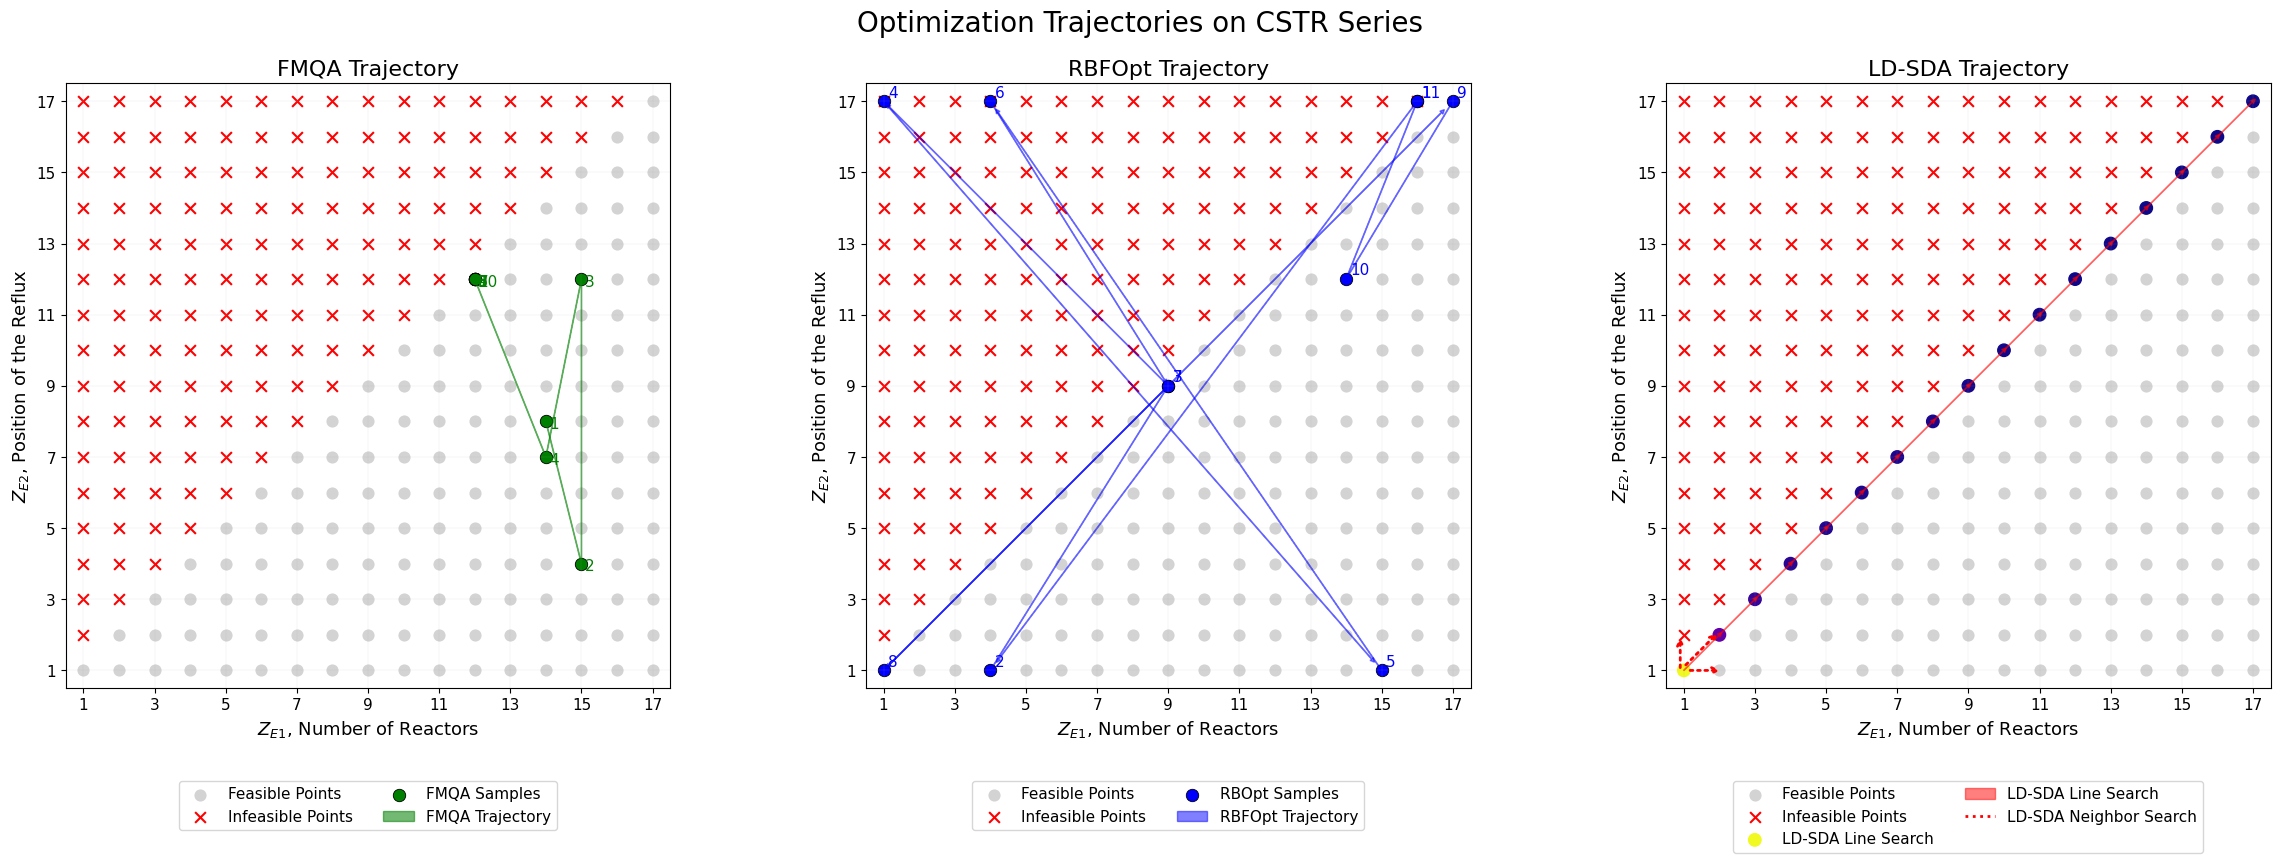

In [11]:
# === 1×3 SUBPLOTS: FMQA | RBFopt | LD-SDA ====================================
import matplotlib.pyplot as plt
import numpy as np

iterations = [
    (1, float("inf"), [16, 17]),
    (2, 3.134337, [4, 1]),
    (3, 2.909511, [9, 9]),
    (4, float("inf"), [1, 17]),
    (5, 3.561959, [15, 1]),
    (6, float("inf"), [4, 17]),
    (7, 2.909511, [9, 9]),
    (8, 9.884852, [1, 1]),
    (9, 2.815251, [17, 17]),
    (10, 3.252993, [14, 12]),
    (11, float("inf"), [16, 17])
]

neighborhood = [
    (9.884851863760804, 1.0, 1.0),
    (4.061881684250354, 2.0, 2.0),
]

line_search = [
    (1,1,9.884851863760804),
    (2,2,4.061881684250354),
    (3,3,3.3148454030723937),
    (4,4,3.1337838981128),
    (5,5,3.06201457641079),
    (6,6,3.0072779729074375),
    (7,7,2.965911187241821),
    (8,8,2.93438026379752,),
    (9,9,2.9095113779790474),
    (10,10,2.88953696810932),
    (11,11,2.873094081299025),
    (12,12,2.8594466153081886),
    (13,13,2.847885348284028),
    (14,14,2.837970119175829),
    (15,15,2.82939406018371),
    (16,16,2.82187639112928),
    (17,17,2.81525078099529)
]

LDSDA_iterations = [
    (1, 9.884851863760804, [1., 1.]),
    (2, float('inf'), [1., 2.]),
    (3, 4.061882, [2., 2.]),
    (4, 4.061882, [2., 1.]),
    (5, 3.3148454030723937, [3., 3.]),
    (6, 3.1337838981128, [4., 4.]),
    (7, 3.06201457641079, [5., 5.]),
    (8, 3.0072779729074375, [6., 6.]),
    (9, 2.965911187241821, [7., 7.]),
    (10, 2.93438026379752, [8., 8.]),
    (11, 2.9095113779790474, [9., 9.]),
    (12, 2.88953696810932, [10., 10.]),
    (13, 2.873094081299025, [11., 11.]),
    (14, 2.8594466153081886, [12., 12.]),
    (15, 2.847885348284028, [13., 13.]),
    (16, 2.837970119175829, [14., 14.]),
    (17, 2.82939406018371, [15., 15.]),
    (18, 2.82187639112928, [16., 16.]),
    (19, 2.81525078099529, [17., 17.])
]

FMQA_iterations = [
    (1, 3.546165612, [14, 8]),
    (2, 3.561946607, [15, 4]),
    (3, 3.399006302, [15, 12]),
    (4, 3.546159260, [14, 7]),
    (5, 2.859446615, [12, 12]),
    (6, 2.859446615, [12, 12]),
    (7, 2.859446615, [12, 12]),
    (8, 2.859446615, [12, 12]),
    (9, 2.859446615, [12, 12]),
    (10, 2.859446615, [12, 12])
]

# If xs, ys weren’t created earlier, build a 17×17 lattice
try:
    xs, ys
except NameError:
    xs, ys = zip(*[(i, j) for i in range(1, 18) for j in range(1, 18)])

# Infeasible mask (y > x)
infeasible_mask = [(i, j) for i in range(1, 18) for j in range(1, 18) if j > i]

# --- Unpack data you already have ---
trajectory_x = [p[2][0] for p in iterations]
trajectory_y = [p[2][1] for p in iterations]
trajectory_obj = [p[1]     for p in iterations]

line_search_x = [p[0] for p in line_search]
line_search_y = [p[1] for p in line_search]
line_search_obj = [p[2] for p in line_search]

fmqa_x = [t[2][0] for t in FMQA_iterations]
fmqa_y = [t[2][1] for t in FMQA_iterations]
fmqa_obj = [t[1]     for t in FMQA_iterations]

def base_panel(ax, title):
    ax.set_aspect('equal', 'box')
    ax.scatter(xs, ys, c='lightgray', s=60, label='Feasible Points')
    if infeasible_mask:
        ax.scatter(*zip(*infeasible_mask), c='red', s=60, marker='x', label='Infeasible Points')
    ax.set_xlim(0.5, 17.5)
    ax.set_ylim(0.5, 17.5)
    ax.set_xticks(range(1, 18, 2))
    ax.set_yticks(range(1, 18, 2))
    ax.set_xlabel(r'$Z_{E1}$, Number of Reactors', fontsize=13)
    ax.set_ylabel(r'$Z_{E2}$, Position of the Reflux', fontsize=13)
    ax.set_title(title, fontsize=16)
    ax.grid(True, linewidth=0.3, alpha=0.3)
    ax.tick_params(labelsize=11)

fig, axs = plt.subplots(1, 3, figsize=(24, 8))  # (FMQA, RBFopt, LD-SDA)

# ------------------------ (1) FMQA PANEL ------------------------
ax = axs[0]
base_panel(ax, 'FMQA Trajectory')

# Samples
ax.scatter(fmqa_x, fmqa_y, c='green', s=80, marker='o',
           edgecolors='black', linewidths=0.6, label='FMQA Samples')
# Arrows
for i in range(len(fmqa_x) - 1):
    ax.arrow(fmqa_x[i], fmqa_y[i],
             0.98*(fmqa_x[i+1] - fmqa_x[i]), 0.98*(fmqa_y[i+1] - fmqa_y[i]),
             head_width=0.12, head_length=0.12, width=0.012,
             fc='green', ec='green', alpha=0.55,
             label='FMQA Trajectory' if i == 0 else '')
# Iteration labels
for k, (x, y) in enumerate(zip(fmqa_x, fmqa_y), start=1):
    ax.text(x + 0.1, y - 0.2, str(k), fontsize=11, color='green')

ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=11)

# ------------------------ (2) RBFopt PANEL ------------------------
ax = axs[1]
base_panel(ax, 'RBFOpt Trajectory')

sc_rb = ax.scatter(
    trajectory_x, trajectory_y,
    c='blue', s=80, edgecolors='black', linewidths=0.6,
    label='RBOpt Samples'
)

# Arrows
for i in range(len(trajectory_x) - 1):
    ax.arrow(trajectory_x[i], trajectory_y[i],
             0.98*(trajectory_x[i+1] - trajectory_x[i]), 0.98*(trajectory_y[i+1] - trajectory_y[i]),
             head_width=0.12, head_length=0.12, width=0.012,
             fc='blue', ec='blue', alpha=0.5,
             label='RBFOpt Trajectory' if i == 0 else '')
    
# Iteration labels for RBFopt (blue)
for k, (x, y) in enumerate(zip(trajectory_x, trajectory_y), start=1):
    ax.text(x + 0.12, y + 0.12, str(k), fontsize=11, color='blue', zorder=6)


# # Colorbar (attached to this axes)
# cbar_rb = fig.colorbar(sc_rb, ax=ax, shrink=0.8, pad=0.02)
# cbar_rb.set_label('Objective Value', fontsize=12)
# cbar_rb.ax.tick_params(labelsize=10)

ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=11)

# ------------------------ (3) LD-SDA PANEL ------------------------
ax = axs[2]
base_panel(ax, 'LD-SDA Trajectory')

sc_ld = ax.scatter(line_search_x, line_search_y, c=line_search_obj, cmap='plasma', s=80,
                   label='LD-SDA Line Search')
# Line search arrows (solid red)
for i in range(len(line_search_x) - 1):
    ax.arrow(line_search_x[i], line_search_y[i],
             0.98*(line_search_x[i+1] - line_search_x[i]), 0.98*(line_search_y[i+1] - line_search_y[i]),
             head_width=0.12, head_length=0.12, width=0.012,
             fc='red', ec='red', alpha=0.5,
             label='LD-SDA Line Search' if i == 0 else '')
# Neighbor search (dotted red) from base [1,1]
base = np.array([1, 1])
neighbors = np.array([[1, 2], [2, 2], [2, 1]])
offsets = [np.array([-0.1, 0]), np.array([0, 0.1]), np.array([0.1, 0])]
ax.plot([], [], linestyle='dotted', color='red', lw=2, label='LD-SDA Neighbor Search')
for neighbor, offset in zip(neighbors, offsets):
    start = base + offset
    end = neighbor + offset
    ax.annotate("",
                xy=end, xycoords='data',
                xytext=start, textcoords='data',
                arrowprops=dict(arrowstyle="->",
                                linestyle="dotted",
                                color="red",
                                lw=2))

# # Colorbar for LD-SDA panel
# cbar_ld = fig.colorbar(sc_ld, ax=ax, shrink=0.8, pad=0.02)
# cbar_ld.set_label('Objective Value', fontsize=12)
# cbar_ld.ax.tick_params(labelsize=10)

ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=11)

# ------------------------ Layout ------------------------
fig.suptitle('Optimization Trajectories on CSTR Series', fontsize=20, y=1.02)
fig.tight_layout(w_pad=2.2)
# (Optional) save
# fig.savefig("trajectories_1x3.png", dpi=200, bbox_inches="tight")


MovieWriter ffmpeg unavailable; using Pillow instead.


('gif/cstr_rbfopt_iteration1_start.gif', None)

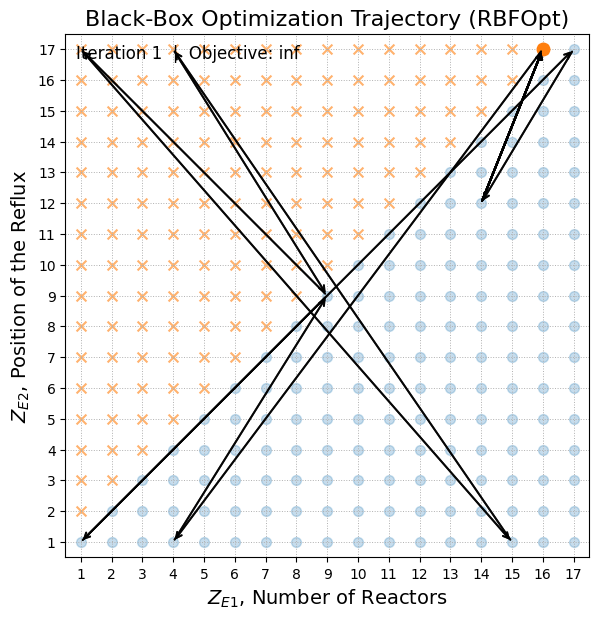

In [5]:
# Recreate final animation:
# - Start iteration numbering from 1
# - Keep all features: feasible/infeasible masks, arrows, pause at final, yellow final dot

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter

rbfopt_iterations =  [
    (1, float("inf"), [16, 17]),
    (2, 3.134337, [4, 1]),
    (3, 2.909511, [9, 9]),
    (4, float("inf"), [1, 17]),
    (5, 3.561959, [15, 1]),
    (6, float("inf"), [4, 17]),
    (7, 2.909511, [9, 9]),
    (8, 9.884852, [1, 1]),
    (9, 2.815251, [17, 17]),
    (10, 3.252993, [14, 12]),
    (11, float("inf"), [16, 17])
]


rbf_x = [p[2][0] for p in rbfopt_iterations]
rbf_y = [p[2][1] for p in rbfopt_iterations]
rbf_obj = [p[1] for p in rbfopt_iterations]

# For dynamic cases
opt_idx = len(rbf_x) - 3
last_idx = len(rbf_x) - 1

# Feasible/infeasible masks
feasible_mask = [ (17, 1), (17, 2), (17, 3), (17, 4), (17, 5), (17, 6), (17, 7), (17, 8), (17, 9), (17, 10), (17, 11), (17, 12), (17, 13), (17, 14), (17, 15), (17, 16), (17, 17),
                  (16, 1), (16, 2), (16, 3), (16, 4), (16, 5), (16, 6), (16, 7), (16, 8), (16, 9), (16, 10), (16, 11), (16, 12), (16, 13), (16, 14), (16, 15), (16, 16),
                  (15, 1), (15, 2), (15, 3), (15, 4), (15, 5), (15, 6), (15, 7), (15, 8), (15, 9), (15, 10), (15, 11), (15, 12), (15, 13), (15, 14), (15, 15),
                  (14, 1), (14, 2), (14, 3), (14, 4), (14, 5), (14, 6), (14, 7), (14, 8), (14, 9), (14, 10), (14, 11), (14, 12), (14, 13), (14, 14),
                  (13, 1), (13, 2), (13, 3), (13, 4), (13, 5), (13, 6), (13, 7), (13, 8), (13, 9), (13, 10), (13, 11), (13, 12), (13, 13),
                  (12, 1), (12, 2), (12, 3), (12, 4), (12, 5), (12, 6), (12, 7), (12, 8), (12, 9), (12, 10), (12, 11), (12, 12),
                  (11, 1), (11, 2), (11, 3), (11, 4), (11, 5), (11, 6), (11, 7), (11, 8), (11, 9), (11, 10), (11, 11),
                  (10, 1), (10, 2), (10, 3), (10, 4), (10, 5), (10, 6), (10, 7), (10, 8), (10, 9), (10, 10),
                  (9, 1), (9, 2), (9, 3), (9, 4), (9, 5), (9, 6), (9, 7), (9, 8), (9, 9),
                  (8, 1), (8, 2), (8, 3), (8, 4), (8, 5), (8, 6), (8, 7),(8, 8),
                  (7, 1), (7, 2), (7, 3), (7, 4), (7, 5), (7, 6), (7, 7),
                  (6, 1), (6, 2), (6, 3), (6, 4), (6, 5), (6, 6),
                  (5, 1), (5, 2), (5, 3), (5, 4), (5, 5),
                  (4, 1), (4, 2), (4, 3), (4, 4),
                  (3, 1), (3, 2), (3, 3),
                  (2, 1), (2, 2),
                  (1, 1)
]
infeasible_mask = [(1, 2), (1, 3), (1, 4), (1, 5), (1, 6), (1, 7), (1, 8), (1, 9), (1, 10), (1, 11), (1, 12), (1, 13), (1, 14), (1, 15), (1, 16), (1, 17),
    (2, 3), (2, 4), (2, 5), (2, 6), (2, 7), (2, 8), (2, 9), (2, 10), (2, 11), (2, 12), (2, 13), (2, 14), (2, 15), (2, 16), (2, 17),
    (3, 4), (3, 5), (3, 6), (3, 7), (3, 8), (3, 9), (3, 10), (3, 11), (3, 12), (3, 13), (3, 14), (3, 15), (3, 16), (3, 17),
    (4, 5), (4, 6), (4, 7), (4, 8), (4, 9), (4, 10), (4, 11), (4, 12), (4, 13), (4, 14), (4, 15), (4, 16), (4, 17),
    (5, 6), (5, 7), (5, 8), (5, 9), (5, 10), (5, 11), (5, 12), (5, 13), (5, 14), (5, 15), (5, 16), (5, 17),
    (6, 7), (6, 8), (6, 9), (6, 10), (6, 11), (6, 12), (6, 13), (6, 14), (6, 15), (6, 16), (6, 17),
    (7, 8), (7, 9), (7, 10), (7, 11), (7, 12), (7, 13), (7, 14), (7, 15), (7, 16), (7, 17),
    (8, 9), (8, 10), (8, 11), (8, 12), (8, 13), (8, 14), (8, 15), (8, 16), (8, 17),
    (9, 10), (9, 11), (9, 12), (9, 13), (9, 14), (9, 15), (9, 16), (9, 17),
    (10, 11), (10, 12), (10, 13), (10, 14), (10, 15), (10, 16), (10, 17),
    (11, 12), (11, 13), (11, 14), (11, 15), (11, 16), (11, 17),
    (12, 13), (12, 14), (12, 15), (12, 16), (12, 17),
    (13, 14), (13, 15), (13, 16), (13, 17),
    (14, 15), (14, 16), (14, 17),
    (15, 16), (15, 17),
    (16, 17)
]

fig, ax = plt.subplots(figsize=(6.8, 6.8))
ax.set_aspect('equal', 'box')
ax.set_xlim(0.5, 17.5)
ax.set_ylim(0.5, 17.5)
ax.set_xticks(range(1, 18))
ax.set_yticks(range(1, 18))
ax.grid(True, linestyle=':', linewidth=0.7)
ax.set_xlabel(r'$Z_{E1}$, Number of Reactors', fontsize=14)
ax.set_ylabel(r'$Z_{E2}$, Position of the Reflux', fontsize=14)
ax.set_title('Black-Box Optimization Trajectory (RBFOpt)', fontsize=16)

# Masks
if feasible_mask:
    fx, fy = zip(*feasible_mask)
    ax.scatter(fx, fy, s=50, marker='o', alpha=0.25, label='Feasible points (mask)')
if infeasible_mask:
    ix, iy = zip(*infeasible_mask)
    ax.scatter(ix, iy, s=50, marker='x', alpha=0.6, label='Infeasible points (mask)')

# Trajectory and markers
line, = ax.plot([], [], marker='o', linestyle='-', label='RBFOpt trajectory')
point, = ax.plot([], [], marker='o', markersize=9)
final_point, = ax.plot([], [], marker='o', markersize=14, linestyle='',
                       markeredgecolor='black', markerfacecolor='yellow')
back_line, = ax.plot([], [], linestyle='--', linewidth=1.5)  # dashed "return" segment
text = ax.text(0.02, 0.98, '', transform=ax.transAxes, va='top', fontsize=12)
# ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=True)

arrows = []

def update(k):
    n = len(rbf_x)

    # 1..n (forward play + pause). NO yellow on last sample.
    if k <= n:
        line.set_data(rbf_x[:k], rbf_y[:k])
        point.set_data([rbf_x[k-1]], [rbf_y[k-1]])
        text.set_text(f'Iteration {k}  |  Objective: {rbf_obj[k-1]:.3f}')

        if k >= 2:
            a = ax.annotate("",
                            xy=(rbf_x[k-1], rbf_y[k-1]), xycoords='data',
                            xytext=(rbf_x[k-2], rbf_y[k-2]), textcoords='data',
                            arrowprops=dict(arrowstyle="->", lw=1.4, alpha=0.85))
            arrows.append(a)

        # <<< KEY CHANGE: keep yellow OFF even at the final sample >>>
        final_point.set_data([], [])

        back_line.set_data([], [])
        return line, point, final_point, text, back_line, *arrows

    # n+1: draw dashed return to optimal and show yellow at optimal
    if k == n + 1:
        line.set_data(rbf_x, rbf_y)
        point.set_data([], [])

        back_line.set_data([rbf_x[last_idx], rbf_x[opt_idx]],
                           [rbf_y[last_idx], rbf_y[opt_idx]])
        final_point.set_data([rbf_x[opt_idx]], [rbf_y[opt_idx]])

        text.set_text(
            f'Final sample at Iter {n}. Optimal at Iter {opt_idx+1}  |  Obj: {rbf_obj[opt_idx]:.3f}'
        )
        return line, point, final_point, text, back_line, *arrows

# Frames: play 1..n, then hold at n, then one extra frame (n+1) to return to optimal, then hold
n = len(rbf_x)
frames = list(range(1, n + 1)) + [n] * 8 + [n + 1] + [n + 1] * 6
anim = FuncAnimation(fig, update, frames=frames, interval=1200, blit=False)

gif_path = "gif/cstr_rbfopt_iteration1_start.gif"
mp4_path = "mp4/cstr_rbfopt_iteration1_start.mp4"

anim.save(gif_path, writer=PillowWriter(fps=1))
try:
    anim.save(mp4_path, fps=1)
except Exception:
    mp4_path = None

gif_path, mp4_path

gif/cstr_ldsda_trajectory.gif None


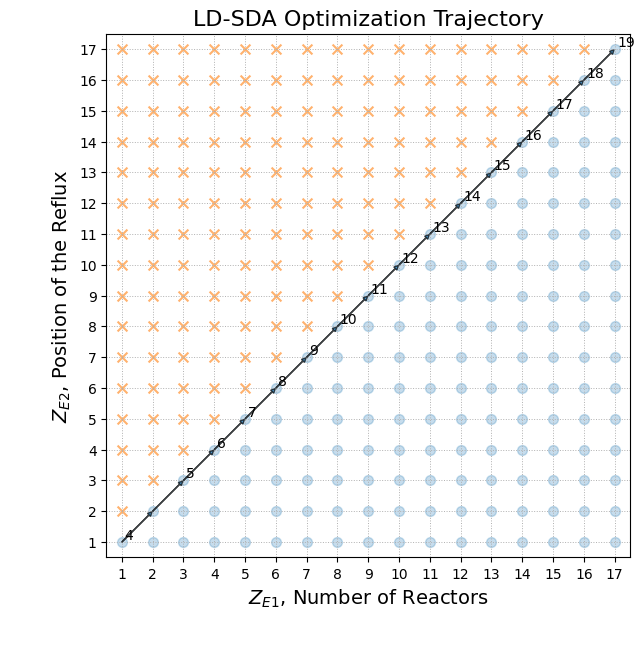

In [18]:
# LD-SDA Animation (unified dotted scatter for both feasible & infeasible)
# - Feasible and infeasible background points are rendered as small '.' markers
#   with the SAME default color (no contrasting colors, no 'x' markers).
# - Neighbor search iterations are counted and shown first; then line search.
# - Exports GIF + MP4.
from matplotlib.animation import FuncAnimation, PillowWriter, FFMpegWriter

line_search = [
    (1,1,9.884851863760804),
    (2,2,4.061881684250354),
    (3,3,3.3148454030723937),
    (4,4,3.1337838981128),
    (5,5,3.06201457641079),
    (6,6,3.0072779729074375),
    (7,7,2.965911187241821),
    (8,8,2.93438026379752,),
    (9,9,2.9095113779790474),
    (10,10,2.88953696810932),
    (11,11,2.873094081299025),
    (12,12,2.8594466153081886),
    (13,13,2.847885348284028),
    (14,14,2.837970119175829),
    (15,15,2.82939406018371),
    (16,16,2.82187639112928),
    (17,17,2.81525078099529)
]

ls_x  = [p[0] for p in line_search]
ls_y  = [p[1] for p in line_search]
ls_obj= [p[2] for p in line_search]

# Masks (feasible: y <= x, infeasible: y > x)
feasible_mask   = [(i, j) for i in range(1, 18) for j in range(1, 18) if j <= i]
infeasible_mask = [(i, j) for i in range(1, 18) for j in range(1, 18) if j > i]

# Neighbor search (from base [1,1] to its three neighbors)
base = np.array([1.0, 1.0])
neighbors = np.array([[1.0, 2.0], [2.0, 2.0], [2.0, 1.0]])

# Already explored point that should not bump the iteration label
skip_label_point = (2, 2)

# -------------------- APPEARANCE KNOBS --------------------
PAST_PT_SIZE     = 22.0           # size for past samples (small)
CURR_START_SIZE  = 38.0           # starting size for current point at early steps
CURR_END_SIZE    = 24.0           # ending size for current point (shrinks over time)
ARROW_WIDTH      = 0.010
HEAD_W, HEAD_L   = 0.14, 0.14

Z_BG      = 1    # masks
Z_ARROWS  = 3
Z_POINTS  = 5
Z_LABELS  = 6
Z_FINAL   = 10   # final yellow dot

# -------------------- FIGURE --------------------
fig, ax = plt.subplots(figsize=(6.8, 6.8))
ax.set_aspect('equal', 'box')

# Background masks (same style as your reference; add c='blue'/'red' if you want colors)
if feasible_mask:
    fx, fy = zip(*feasible_mask)
    ax.scatter(fx, fy, s=50, marker='o', alpha=0.25,
               label='Feasible points (mask)', zorder=Z_BG)
if infeasible_mask:
    ix, iy = zip(*infeasible_mask)
    ax.scatter(ix, iy, s=50, marker='x', alpha=0.6,
               label='Infeasible points (mask)', zorder=Z_BG)

ax.set_xlim(0.5, 17.5)
ax.set_ylim(0.5, 17.5)
ax.set_xticks(range(1, 18))
ax.set_yticks(range(1, 18))
ax.grid(True, linestyle=':', linewidth=0.7)
ax.set_xlabel(r'$Z_{E1}$, Number of Reactors', fontsize=14)
ax.set_ylabel(r'$Z_{E2}$, Position of the Reflux', fontsize=14)
ax.set_title('LD-SDA Optimization Trajectory', fontsize=16)

# -------------------- ARTISTS --------------------
neighbor_arrows, neighbor_labels = [], []
points_scatter = ax.scatter([], [], s=PAST_PT_SIZE, zorder=Z_POINTS)
ls_labels_texts, ls_arrows = [], []
final_point, = ax.plot([], [], marker='o', markersize=14, linestyle='',
                       markeredgecolor='black', markerfacecolor='yellow',
                       zorder=Z_FINAL, clip_on=False)
hud = ax.text(0.02, 0.98, '', transform=ax.transAxes, va='top',
              fontsize=12, zorder=Z_LABELS)

# -------------------- ANIMATION --------------------
frames_neighbors  = len(neighbors)      # 3
frames_linesearch = len(ls_x)           # 17
pause_frames      = 12
total_frames      = frames_neighbors + frames_linesearch + 1 + pause_frames

# Current-point size schedule (shrinks along the line search)
size_schedule = np.linspace(CURR_START_SIZE, CURR_END_SIZE, frames_linesearch)

iter_counter = {'val': 0}  # includes neighbor + line search (skips (2,2))

def init():
    points_scatter.set_offsets(np.empty((0, 2)))
    points_scatter.set_sizes(np.empty((0,)))
    final_point.set_data([], [])
    hud.set_text('')
    return [points_scatter, final_point, hud]

def update(frame):
    # ---- Phase A: neighbor search (iterations 1..3) ----
    if frame < frames_neighbors:
        start = base
        end   = neighbors[frame]
        arr = ax.annotate("",
                          xy=end, xycoords='data',
                          xytext=start, textcoords='data',
                          arrowprops=dict(arrowstyle="->", linestyle="dotted", lw=2),
                          zorder=Z_ARROWS)
        neighbor_arrows.append(arr)

        iter_counter['val'] += 1
        lbl = ax.text(end[0] + 0.1, end[1] + 0.1, str(iter_counter['val']),
                      fontsize=10, zorder=Z_LABELS)
        neighbor_labels.append(lbl)

        hud.set_text(f'Neighbor search — Iteration {iter_counter["val"]}')
        final_point.set_data([], [])
        return neighbor_arrows + neighbor_labels + [points_scatter, final_point, hud]

    # ---- Transition: clear neighbor visuals ----
    if frame == frames_neighbors:
        for a in neighbor_arrows: a.remove()
        neighbor_arrows.clear()
        for l in neighbor_labels: l.remove()
        neighbor_labels.clear()

    # ---- Phase B: line search with shrinking current point ----
    idx = frame - frames_neighbors
    if idx < frames_linesearch:
        pts = np.column_stack([ls_x[:idx+1], ls_y[:idx+1]])
        points_scatter.set_offsets(pts)

        sizes = np.full(idx+1, PAST_PT_SIZE, dtype=float)
        sizes[-1] = size_schedule[idx]      # shrink current point over time
        points_scatter.set_sizes(sizes)

        x, y = ls_x[idx], ls_y[idx]

        # arrows drawn beneath points
        if idx > 0:
            dx = ls_x[idx] - ls_x[idx-1]
            dy = ls_y[idx] - ls_y[idx-1]
            arr = ax.arrow(ls_x[idx-1], ls_y[idx-1],
                           0.98*dx, 0.98*dy,
                           head_width=HEAD_W, head_length=HEAD_L, width=ARROW_WIDTH,
                           length_includes_head=True, alpha=0.7, zorder=Z_ARROWS)
            ls_arrows.append(arr)

        if (x, y) != skip_label_point:
            iter_counter['val'] += 1
            lbl = ax.text(x + 0.08, y + 0.08, str(iter_counter['val']),
                          fontsize=10, zorder=Z_LABELS)
            ls_labels_texts.append(lbl)

        final_point.set_data([], [])  # ensure nothing can cover it later
        hud.set_text(f'Line search — Iteration {iter_counter["val"]} | Current Obj: {ls_obj[idx]:.3f}')
        return ls_arrows + ls_labels_texts + [points_scatter, final_point, hud]

    # ---- Final highlight & pause ----
    if idx == frames_linesearch:
        # draw after everything, highest zorder, and clip_off so arrows can't hide it
        final_point.set_data([ls_x[-1]], [ls_y[-1]])
        final_obj = ls_obj[-1]
        hud.set_text(
            f'Final — Total Iterations: {iter_counter["val"]} | '
            f'Final Obj: {final_obj:.3f}'
        )
        return ls_arrows + ls_labels_texts + [points_scatter, final_point, hud]

anim = FuncAnimation(fig, update, init_func=init,
                     frames=total_frames, interval=1200, blit=False, repeat=False)

# -------------------- EXPORT --------------------
gif_path = "gif/cstr_ldsda_trajectory.gif"
anim.save(gif_path, writer=PillowWriter(fps=1))

mp4_path = "mp4/cstr_ldsda_trajectory.mp4"
try:
    writer = FFMpegWriter(fps=1000/350, metadata=dict(artist='Albert+GPT'), bitrate=1800)
    anim.save(mp4_path, writer=writer)
except Exception:
    mp4_path = None

print(gif_path, mp4_path)